# Multilingual relatedness: model and experiments
This main notebook contains the core text normalization, pair features, model, weighted regression/ranking losses, training loop, scorer and saved-head prediction code. The encoder is pinned AfroXLMR; no random pooler is used.

The recorded studies trained three ridge regressors and eighteen MLP heads. This notebook reruns the already fixed ranking-weight 0.1/seed 42 configuration on authentic train/development features to verify reproducibility. It is not a new model-selection candidate. Test gold is never loaded by notebook code.

Validation improved, but the final learned model lost to character overlap on heldout rank correlation. It reduced MAE instead. Those measured outcomes remain visible below and in the results notebook.

In [1]:
from pathlib import Path
import sys,json,math,hashlib,time,copy
from datetime import datetime,timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib','inline')
ROOT=Path.cwd().resolve()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
PROCESSED=ROOT/'data/processed/semrel-lf-v1'
CACHE=ROOT/'data/features/afro-xlmr-v1'
FIGURES=ROOT/'assets/figures'
FIGURES.mkdir(parents=True,exist_ok=True)
def show(fig,name):
    fig.tight_layout(pad=1.5,w_pad=3)
    fig.savefig(FIGURES/name,dpi=140,bbox_inches='tight');display(fig);plt.close(fig)
def report(name):return json.loads((ROOT/'docs'/name).read_text(encoding='utf-8'))

In [2]:
import torch
from scipy.stats import spearmanr,pearsonr
from src.config import LANGUAGES,MODEL_ID,MODEL_REVISION
from src.models.train import load_split,validate_bundle
torch.set_num_threads(2)
print({'torch':str(torch.__version__),'threads':torch.get_num_threads(),'model':MODEL_ID,'revision':MODEL_REVISION,'local_encoder_allocated':False})

{'torch': '2.14.0+cpu', 'threads': 2, 'model': 'Davlan/afro-xlmr-base', 'revision': '25f27299c247a6b73a767bd82d12444138b19337', 'local_encoder_allocated': False}


## Text preprocessing and symmetric pair features
Original text enters the encoder. NFKC/casefold/whitespace normalization is used only for lexical overlap and pair-copy audits. Absolute difference, elementwise product, cosine and lexical scores are symmetric in sentence order. No target, PairID or split indicator enters features.

In [3]:
import unicodedata,re

def normalized(text):
    return ' '.join(unicodedata.normalize('NFKC',text).casefold().split())

def jaccard(a,b):
    union=a|b
    return len(a&b)/len(union) if union else 0.

def lexical(rows):
    values=[]
    for row in rows:
        a,b=normalized(row['sentence1']),normalized(row['sentence2'])
        words=lambda text:set(re.findall(r'\w+',text,flags=re.UNICODE))
        grams=lambda text:{text[i:i+3] for i in range(max(0,len(text)-2))}
        values.append([jaccard(words(a),words(b)),jaccard(grams(a),grams(b))])
    return np.asarray(values,dtype=np.float32)

def pair_features(embeddings,rows):
    e=np.asarray(embeddings,dtype=np.float32)
    if e.ndim!=3 or e.shape[:2]!=(len(rows),2) or not len(rows) or not np.isfinite(e).all():
        raise ValueError('Expected aligned finite pair embeddings')
    norms=np.linalg.norm(e.astype(np.float64),axis=2,keepdims=True)
    if (norms<=0).any():raise ValueError('Zero embedding')
    e=(e/norms).astype(np.float32)
    a,b=e[:,0],e[:,1]
    cosine=np.sum(a*b,axis=1,keepdims=True)
    values=np.concatenate([np.abs(a-b),a*b,cosine,lexical(rows)],axis=1)
    if not np.isfinite(values).all():raise ValueError('Nonfinite pair features')
    return values

def fit_scaler(values):
    x=np.asarray(values,dtype=np.float64)
    if x.ndim!=2 or not len(x) or not np.isfinite(x).all():raise ValueError('Finite nonempty training features required')
    return x.mean(axis=0).astype(np.float32),np.maximum(x.std(axis=0),1e-5).astype(np.float32)

def scale(values,mean,std):
    x=np.asarray(values,dtype=np.float32);mean=np.asarray(mean);std=np.asarray(std)
    if x.ndim!=2 or mean.shape!=(x.shape[1],) or std.shape!=mean.shape or not np.isfinite(mean).all() or not np.isfinite(std).all() or (std<=0).any():
        raise ValueError('Invalid persisted normalization')
    result=(x-mean)/std
    if not np.isfinite(result).all():raise ValueError('Nonfinite normalized features')
    return result

## Frozen encoder
The complete local wrapper is shown, including strict loading, attention-mask mean pooling, unit normalization and truncation counts. It is defined but not allocated on this host; actual cloud inference and weight hashes are recorded.

In [4]:
class Encoder:
    def __init__(self,device='cpu'):
        import torch
        from transformers import AutoModel,AutoTokenizer
        torch.set_num_threads(2)
        self.torch=torch;self.device=device
        self.tokenizer=AutoTokenizer.from_pretrained(MODEL_ID,revision=MODEL_REVISION,trust_remote_code=False)
        self.model,loading=AutoModel.from_pretrained(MODEL_ID,revision=MODEL_REVISION,
            add_pooling_layer=False,output_loading_info=True,trust_remote_code=False)
        if loading.get('missing_keys') or loading.get('mismatched_keys') or loading.get('error_msgs'):
            raise ValueError('Pretrained encoder failed strict loading')
        if any(not key.startswith('lm_head.') for key in loading.get('unexpected_keys',[])):
            raise ValueError('Unexpected pretrained encoder keys')
        self.model=self.model.to(device).eval().requires_grad_(False)
        self.loading=loading

    def encode(self,texts,batch_size=16):
        if not texts or any(not isinstance(t,str) or not t.strip() for t in texts):raise ValueError('Nonempty text required')
        values=[];truncated=0
        for start in range(0,len(texts),batch_size):
            batch=texts[start:start+batch_size]
            lengths=self.tokenizer(batch,add_special_tokens=True,truncation=False)['input_ids']
            truncated+=sum(len(row)>128 for row in lengths)
            tokens=self.tokenizer(batch,padding=True,truncation=True,max_length=128,return_tensors='pt').to(self.device)
            with self.torch.inference_mode():
                state=self.model(**tokens).last_hidden_state
                mask=tokens['attention_mask'].unsqueeze(-1).to(state.dtype)
                pooled=(state*mask).sum(1)/mask.sum(1).clamp_min(1)
                pooled=self.torch.nn.functional.normalize(pooled,p=2,dim=1)
            if not self.torch.isfinite(pooled).all():raise ValueError('Nonfinite encoder output')
            values.append(pooled.cpu().numpy())
        return np.concatenate(values).astype(np.float32),{'sentences':len(texts),'truncated_sentences':truncated}

## Language-macro scorer and promotion rule
Spearman is the primary objective, with equal language weights. Constant predictions produce undefined rank correlation and cannot be promoted. Per-language regression guards prevent a macro gain from hiding a large language loss.

In [5]:
def evaluate(target,prediction,languages):
    y=np.asarray(target,dtype=float);p=np.asarray(prediction,dtype=float);langs=np.asarray(languages)
    if y.ndim!=1 or y.shape!=p.shape or y.shape!=langs.shape or not len(y) or not np.isfinite(y).all() or not np.isfinite(p).all():
        raise ValueError('Aligned finite predictions and targets required')
    if ((y<0)|(y>1)).any() or ((p<0)|(p>1)).any() or set(langs)!=set(LANGUAGES):
        raise ValueError('Expected three supported languages and scores in[0,1]')
    result={}
    for language in LANGUAGES:
        mask=langs==language;a,b=y[mask],p[mask]
        nonconstant=len(a)>1 and np.ptp(a)>0 and np.ptp(b)>0
        result[language]={'spearman':float(spearmanr(a,b).statistic) if nonconstant else None,
                          'pearson':float(pearsonr(a,b).statistic) if nonconstant else None,
                          'mae':float(np.abs(a-b).mean()),'rows':int(mask.sum())}
    valid=all(row['spearman'] is not None for row in result.values())
    return {'languages':result,'macro_spearman':float(np.mean([row['spearman'] for row in result.values()])) if valid else None,
            'macro_pearson':float(np.mean([row['pearson'] for row in result.values()])) if valid else None,
            'macro_mae':float(np.mean([row['mae'] for row in result.values()]))}

def promotable(candidate,baseline):
    if candidate['macro_spearman'] is None or baseline['macro_spearman'] is None:return False
    return (candidate['macro_spearman']>=baseline['macro_spearman']+.005 and
            all(candidate['languages'][lang]['spearman']>=baseline['languages'][lang]['spearman']-.02 for lang in LANGUAGES))

## Model and language-balanced losses
The 1,539-feature MLP predicts a bounded relatedness score, not a calibrated probability. Ranking pairs come only from existing human training ratings within each language/minibatch; they add no sentences or fabricated target dataset.

In [6]:
class Head(torch.nn.Module):
    def __init__(self,width,hidden=128,dropout=.2):
        super().__init__()
        self.net=torch.nn.Sequential(torch.nn.Linear(width,hidden),torch.nn.ReLU(),torch.nn.Dropout(dropout),torch.nn.Linear(hidden,1),torch.nn.Sigmoid())
    def forward(self,x):return self.net(x).squeeze(-1)

def balanced_weights(languages):
    languages=np.asarray(languages)
    if set(languages)!=set(LANGUAGES):raise ValueError('Training needs all supported languages')
    return np.asarray([len(languages)/(len(LANGUAGES)*np.sum(languages==lang)) for lang in languages],np.float32)

def ranking_loss(logits,targets,languages):
    """Human-score order within each language; no manufactured sentence pairs."""
    values=[]
    for language in LANGUAGES:
        mask=torch.as_tensor(np.asarray(languages)==language,device=logits.device)
        a,b=logits[mask],targets[mask]
        difference=b[:,None]-b[None,:]
        eligible=torch.triu(torch.ones_like(difference,dtype=torch.bool),diagonal=1)&(difference.abs()>=.1)
        if eligible.any():
            logits_difference=a[:,None]-a[None,:]
            values.append(torch.nn.functional.binary_cross_entropy_with_logits(logits_difference[eligible],(difference[eligible]>0).to(logits.dtype)))
    return torch.stack(values).mean() if values else logits.sum()*0

## Actual training loop
AdamW, weighted MSE, optional ranking loss, gradient clipping, finite checks, deterministic seeds and validation checkpoint selection are visible. Each deployed configuration averages three fixed seeds, rather than selecting a lucky seed.

In [7]:
def fit_mlp(x,y,languages,vx,vy,validation_languages,config,seed,epochs=50):
    if epochs<1:raise ValueError('Positive epoch count required')
    torch.manual_seed(seed);torch.set_num_threads(2)
    model=Head(x.shape[1],config['hidden'],config['dropout'])
    optimizer=torch.optim.AdamW(model.parameters(),lr=config['lr'],weight_decay=config['weight_decay'])
    x,y,vx=torch.from_numpy(x),torch.from_numpy(y),torch.from_numpy(vx)
    weights=torch.from_numpy(balanced_weights(languages));generator=torch.Generator().manual_seed(seed)
    history=[];best=-float('inf');best_epoch=0;state=None
    for epoch in range(epochs):
        model.train();total=0.;mse_total=0.;ranking_total=0.
        for ids in torch.randperm(len(x),generator=generator).split(64):
            ranking_weight=config.get('ranking_weight',0.)
            if ranking_weight:
                logits=model.net[:-1](x[ids]).squeeze(-1)
                prediction=torch.sigmoid(logits)
                ranking=ranking_loss(logits,y[ids],np.asarray(languages)[ids.numpy()])
            else:
                prediction=model(x[ids]);ranking=prediction.sum()*0
            regression=((prediction-y[ids]).square()*weights[ids]).mean()
            loss=regression+ranking_weight*ranking
            if not torch.isfinite(loss):raise RuntimeError('Nonfinite training loss')
            optimizer.zero_grad();loss.backward();torch.nn.utils.clip_grad_norm_(model.parameters(),1,error_if_nonfinite=True);optimizer.step()
            total+=float(loss.detach())*len(ids)
            mse_total+=float(regression.detach())*len(ids);ranking_total+=float(ranking.detach())*len(ids)
        model.eval()
        with torch.inference_mode():prediction=model(vx).numpy()
        metrics=evaluate(vy,prediction,validation_languages);value=metrics['macro_spearman']
        history.append({'epoch':epoch+1,'weighted_mse':mse_total/len(x),'ranking_loss':ranking_total/len(x),
                        'training_objective':total/len(x),'validation':metrics})
        if value is not None and value>best:
            best=value;best_epoch=epoch+1;state=copy.deepcopy(model.state_dict())
        if epoch+1>=3 and epoch+1-best_epoch>=6:break
    if state is None:raise ValueError('No eligible nonconstant validation checkpoint')
    model.load_state_dict(state);model.eval()
    with torch.inference_mode():prediction=model(vx).numpy()
    return {'state_dict':state,'config':config,'seed':seed},prediction,{'seed':seed,'best_epoch':best_epoch,
        'history':history,'stop':'validation_plateau' if epoch+1>=3 and epoch+1-best_epoch>=6 else 'epoch_limit'}

## Saved model prediction
The same symmetric features and train-only scaling are used at inference. Ridge coefficients and MLP state are exported as tensors for weights-only loading.

In [8]:
def predict_features(bundle,features):
    validate_bundle(bundle)
    x=np.asarray(features,np.float32)
    if x.ndim!=2 or x.shape[1]!=bundle['width'] or not np.isfinite(x).all():raise ValueError('Invalid inference features')
    kind=bundle['kind']
    if kind=='baseline':
        name=bundle['name']
        prediction={'cosine':(x[:,-3]+1)/2,'word_jaccard':x[:,-2],'character_jaccard':x[:,-1],
                    'train_mean':np.full(len(x),bundle['train_mean'])}[name]
    else:
        normalized=scale(x,bundle['mean'],bundle['std'])
        if kind=='ridge':prediction=normalized@bundle['coefficient'].numpy()+float(bundle['intercept'])
        else:
            predictions=[]
            for component in bundle['components']:
                model=Head(bundle['width'],component['config']['hidden'],component['config']['dropout'])
                model.load_state_dict(component['state_dict'],strict=True);model.eval()
                with torch.inference_mode():predictions.append(model(torch.from_numpy(normalized)).numpy())
            prediction=np.mean(predictions,axis=0)
    return np.clip(prediction,0,1).astype(np.float32)

In [9]:
x,y,languages,train_rows,encoder_receipt=load_split(CACHE,PROCESSED,'train')
vx,vy,validation_languages,dev_rows,_=load_split(CACHE,PROCESSED,'dev')
mean,std=fit_scaler(x);normalized=scale(x,mean,std);validation=scale(vx,mean,std)
display(pd.DataFrame([{'split':'train','rows':len(x),'features':x.shape[1]},{'split':'development','rows':len(vx),'features':vx.shape[1]}]))
print({'encoder_weight_sha256':encoder_receipt['weight_sha256'],'test_targets_loaded':False})

,split,rows,features
0,train,3456,1539
1,development,386,1539


{'encoder_weight_sha256': {'model.safetensors': 'f73b04316c9c2e76fcb213957616a09e1eb44112266717f649fc1897dac42953'}, 'test_targets_loaded': False}


## Genuine full-data replay of one fixed existing fit
This uses the selected objective and seed 42 declared before execution. It writes a fresh private artifact. The recorded global choice remains locked regardless of this replay.

In [10]:
config={'name':'ranking-0.1','hidden':128,'dropout':.2,'lr':.001,'weight_decay':.01,'ranking_weight':.1}
started=time.time()
component,prediction,history=fit_mlp(normalized,y,languages,validation,vy,validation_languages,config,42,epochs=50)
replay_path=ROOT/'models'/('notebook-replay-'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
replay_path.mkdir();torch.save(component,replay_path/'seed-42.pt')
recorded=torch.load(ROOT/'models/heads-v2/ranking-0.1-seed-42.pt',map_location='cpu',weights_only=True)
difference=max(float((component['state_dict'][k]-recorded['state_dict'][k]).abs().max()) for k in component['state_dict'])
display(pd.DataFrame([{'seed':42,'best_epoch':history['best_epoch'],'validation_macro_Spearman':evaluate(vy,prediction,validation_languages)['macro_spearman'],'state_max_difference':difference,'runtime_seconds':time.time()-started}]))
assert difference==0

,seed,best_epoch,validation_macro_Spearman,state_max_difference,runtime_seconds
0,42,5,0.557851,0.0,24.632926


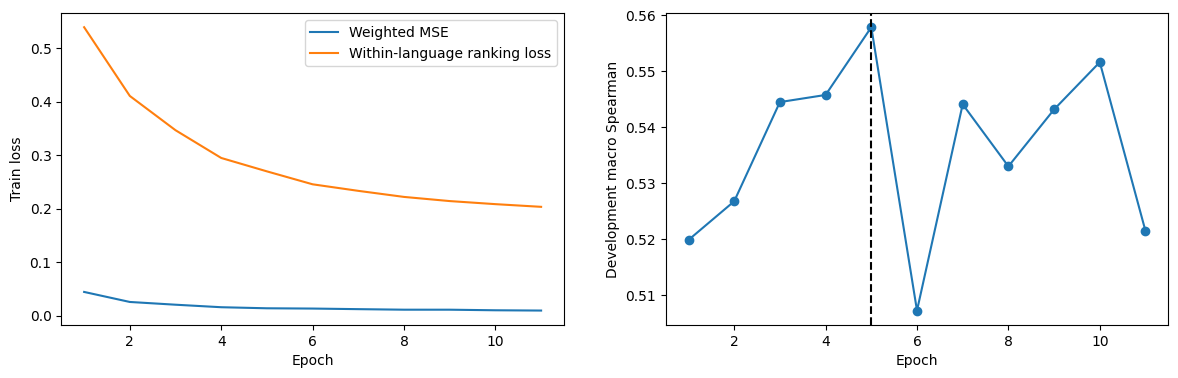

In [11]:
rows=history['history']
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot([r['epoch'] for r in rows],[r['weighted_mse'] for r in rows],label='Weighted MSE')
axes[0].plot([r['epoch'] for r in rows],[r['ranking_loss'] for r in rows],label='Within-language ranking loss')
axes[0].set(xlabel='Epoch',ylabel='Train loss');axes[0].legend()
axes[1].plot([r['epoch'] for r in rows],[r['validation']['macro_spearman'] for r in rows],marker='o')
axes[1].axvline(history['best_epoch'],color='black',linestyle='--');axes[1].set(xlabel='Epoch',ylabel='Development macro Spearman')
show(fig,'sts_training_replay.png')

## Recorded baseline and learned comparisons
These tables come from complete saved studies, not from the one-fit replay. Development selected all procedures before the first final-gold release.

In [12]:
first=report('selection-v1.json');follow=report('selection-v2.json')
records=[]
for study in (first,follow):
    for candidate in study['candidates']:
        records.append({'model':candidate['name'],'macro_Spearman':candidate['validation']['macro_spearman'],'macro_MAE':candidate['validation']['macro_mae'],'seed_SD':candidate.get('seed_sample_std_spearman',np.nan)})
comparison=pd.DataFrame(records)
display(comparison)
print({'first_winner':first['selected'],'final_winner':follow['selected'],'ranking_promoted':follow['improved']})

,model,macro_Spearman,macro_MAE,seed_SD
0,cosine,0.213283,0.500700,NaN
1,word_jaccard,0.376456,0.259472,NaN
2,character_jaccard,0.442957,0.245535,NaN
3,train_mean,NaN,0.200849,NaN
4,ridge-1,0.404502,0.200963,NaN
5,ridge-10,0.408302,0.199077,NaN
6,ridge-100,0.426039,0.187713,NaN
7,mlp128,0.555478,0.159065,0.011019
8,mlp128-slower,0.543189,0.163931,0.003337
9,mlp128-regularized,0.541576,0.160715,0.003180


{'first_winner': 'mlp128', 'final_winner': 'ranking-0.1', 'ranking_promoted': True}


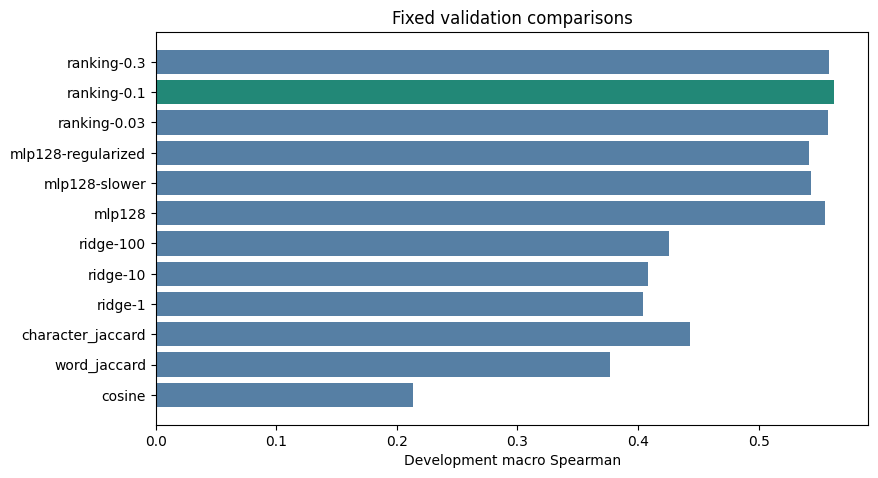

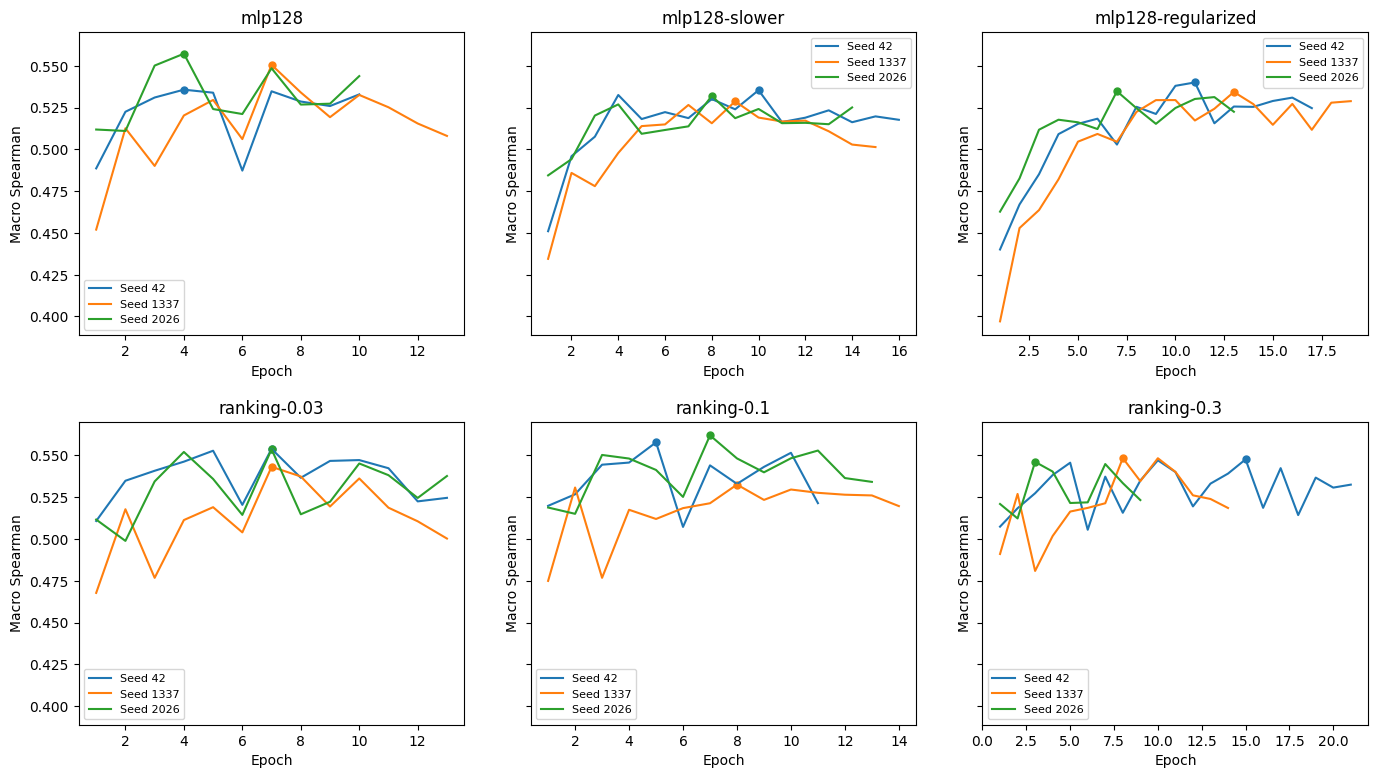

In [13]:
available=comparison.dropna(subset=['macro_Spearman'])
fig,ax=plt.subplots(figsize=(9,5))
colors=['#287' if name==follow['selected'] else '#567fa4' for name in available['model']]
ax.barh(available['model'],available['macro_Spearman'],color=colors)
ax.set(xlabel='Development macro Spearman',title='Fixed validation comparisons')
show(fig,'sts_validation_comparison.png')
candidates=[c for study in (first,follow) for c in study['candidates'] if c.get('fits')]
fig,axes=plt.subplots(2,3,figsize=(14,8),sharey=True)
for ax,candidate in zip(axes.flat,candidates):
    for fit in candidate['fits']:
        epochs=[r['epoch'] for r in fit['history']]
        values=[r['validation']['macro_spearman'] for r in fit['history']]
        line=ax.plot(epochs,values,label='Seed '+str(fit['seed']))[0]
        ax.scatter([fit['best_epoch']],[values[fit['best_epoch']-1]],color=line.get_color(),s=25)
    ax.set(title=candidate['name'],xlabel='Epoch',ylabel='Macro Spearman');ax.legend(fontsize=8)
show(fig,'sts_all_experiment_curves.png')

## Actual selected-checkpoint validation replay
This computes the saved three-seed ensemble with the visible predictor. It compares against the frozen development result and does not open test labels.

In [14]:
bundle=torch.load(ROOT/'models/selected-v1/selected.pt',map_location='cpu',weights_only=True)
saved_prediction=predict_features(bundle,vx)
saved_metrics=evaluate(vy,saved_prediction,validation_languages)
display(pd.DataFrame(saved_metrics['languages']).T)
assert saved_metrics==follow['validation']
display(pd.DataFrame([report('actual-inference-proof-v1.json')]))

,spearman,pearson,mae,rows
amh,0.800608,0.799681,0.122808,95.0
hau,0.577843,0.583135,0.180773,212.0
kin,0.310222,0.324370,0.203923,79.0


,rows,real_source,cache_prediction_max_difference,reversal_max_difference,finite_scores_in_unit_interval,accuracy_claim,test_gold_loaded,checkpoint_sha256,input_sha256,source_manifest_sha256,source_revision,torch,elapsed_seconds
0,6,First training pair per language and reversed ...,1.192093e-07,0.0,True,False,False,293b99ca441829ba9cf36a60ce118384e54c0af8cf791d...,9a99454eebf3ce9e51b9cfaf838c9ec34ddebb729131b9...,7345dd658e93da45293f49150cf25433c137deafd4f0c8...,cfe896d5c928fa3c01a40ac77881839a9bdb0819,2.11.0+cpu,71.188031


The learned model reached development Spearman 0.56289, but final test Spearman was 0.54864 against character overlap's 0.58204. Test MAE improved from 0.23902 to 0.16797. The frozen model was not replaced after seeing that reversal. A source-reusing official split and small development cohorts limit generalization claims.